# Mercado y liquidez: pérdidas, caja y dependencia

## Preguntas y alcance
¿Cómo cambia el déficit de financiación con la reserva inicial? ¿Sumar un costo de financiación a una pérdida de mercado amplifica ES cuando ambos dependen del mismo shock? Se usan escenarios sintéticos, semilla fija y unidades monetarias abstractas.

El déficit máximo es una necesidad de financiación, **no una pérdida de P&L**. Para construir una pérdida conjunta se aplica explícitamente una penalidad de financiación del 20% al déficit. No se estima LCR, NSFR ni capital regulatorio.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
SEED=20261018


## Modelo de escenarios
El shock común z reduce retornos y aumenta salidas y margin calls. Caja se acumula como $C_t=C_0+\sum_{j\leq t}(I_j-O_j-M_j)$. La primera ruptura exige caja estrictamente negativa. Si nunca ocurre, se devuelve H+1, que es un marcador de no ruptura y no una fecha observada.

Las llamadas de margen salen de caja; no se interpretan automáticamente como gasto económico. No hay reposición ni acceso endógeno a liquidez.

In [2]:
from python.laboratorio import tail_risk,liquidity_paths,correlated_stress
market,liquidity=correlated_stress(n_scenarios=6000,horizon=30,seed=SEED,initial_cash=30.)
assert market.shape==(6000,) and liquidity.paths.shape==(6000,30)
assert np.isfinite(market).all() and np.isfinite(liquidity.paths).all()
display(pd.DataFrame({'concepto':['Pérdida de mercado media','Déficit máximo medio','Probabilidad de déficit'],
    'valor':[market.mean(),liquidity.max_shortfall.mean(),liquidity.breach_probability]}))

,concepto,valor
0,Pérdida de mercado media,-0.116058
1,Déficit máximo medio,6.317691
2,Probabilidad de déficit,0.612000


## Reserva inicial y horizonte
Se usa la misma matriz de flujos en todas las reservas. La reserva adicional desplaza toda la trayectoria, por lo que el déficit no puede aumentar. La monotonicidad se comprueba camino por camino, además de comparar medias.

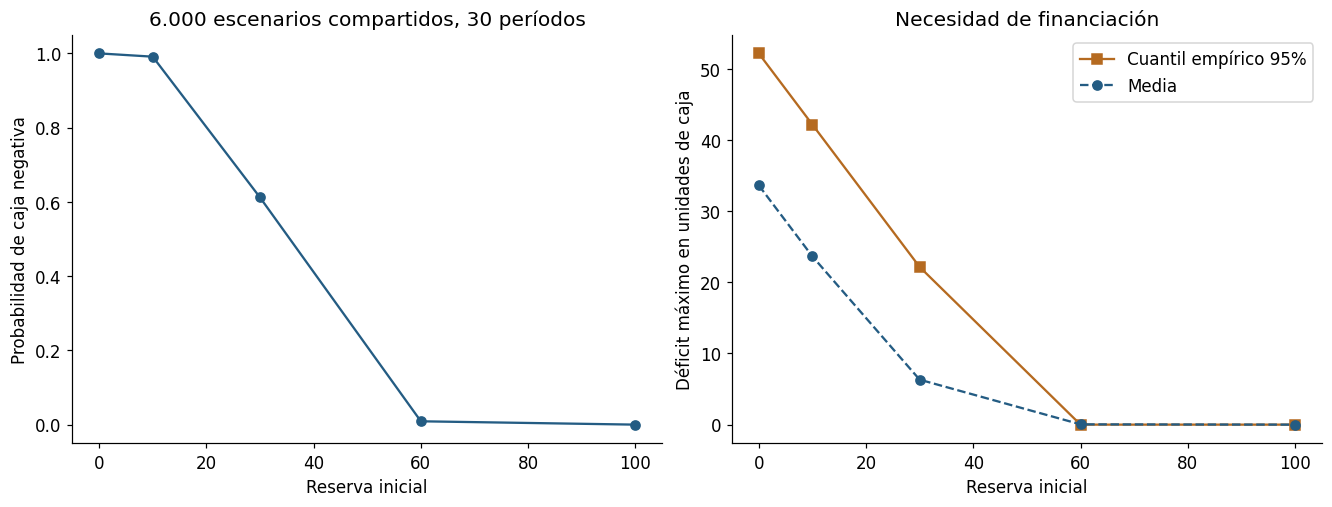

,reserve,breach_probability,mean_peak,q95_peak
0,0.0,1.00000,33.61602,52.14672
1,10.0,0.99117,23.63637,42.14672
2,30.0,0.61200,6.31769,22.14672
3,60.0,0.00900,0.03945,0.00000
4,100.0,0.00000,0.00000,0.00000


In [3]:
reserve_rows=[];previous=None
for initial_cash in [0.,10.,30.,60.,100.]:
    _,result=correlated_stress(6000,30,SEED,initial_cash)
    if previous is not None:assert np.all(result.max_shortfall<=previous+1e-10)
    previous=result.max_shortfall.copy()
    reserve_rows.append(dict(reserve=initial_cash,breach_probability=result.breach_probability,
        mean_peak=result.max_shortfall.mean(),q95_peak=np.quantile(result.max_shortfall,.95,method='inverted_cdf')))
reserve_table=pd.DataFrame(reserve_rows);display(reserve_table.round(5))
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
axes[0].plot(reserve_table.reserve,reserve_table.breach_probability,'o-',color='#245C83')
axes[0].set(xlabel='Reserva inicial',ylabel='Probabilidad de caja negativa',title='6.000 escenarios compartidos, 30 períodos')
axes[1].plot(reserve_table.reserve,reserve_table.q95_peak,'s-',color='#B56A20',label='Cuantil empírico 95%')
axes[1].plot(reserve_table.reserve,reserve_table.mean_peak,'o--',color='#245C83',label='Media')
axes[1].set(xlabel='Reserva inicial',ylabel='Déficit máximo en unidades de caja',title='Necesidad de financiación');axes[1].legend()
plt.show()

## Primer déficit: censura explícita
El histograma distingue escenarios que rompen del conjunto que termina sin romper. Promediar H+1 como si fuera un tiempo de ruptura sesgaría la interpretación. Los cuantiles de la trayectoria son cuantiles transversales, no bandas de confianza de un camino individual.

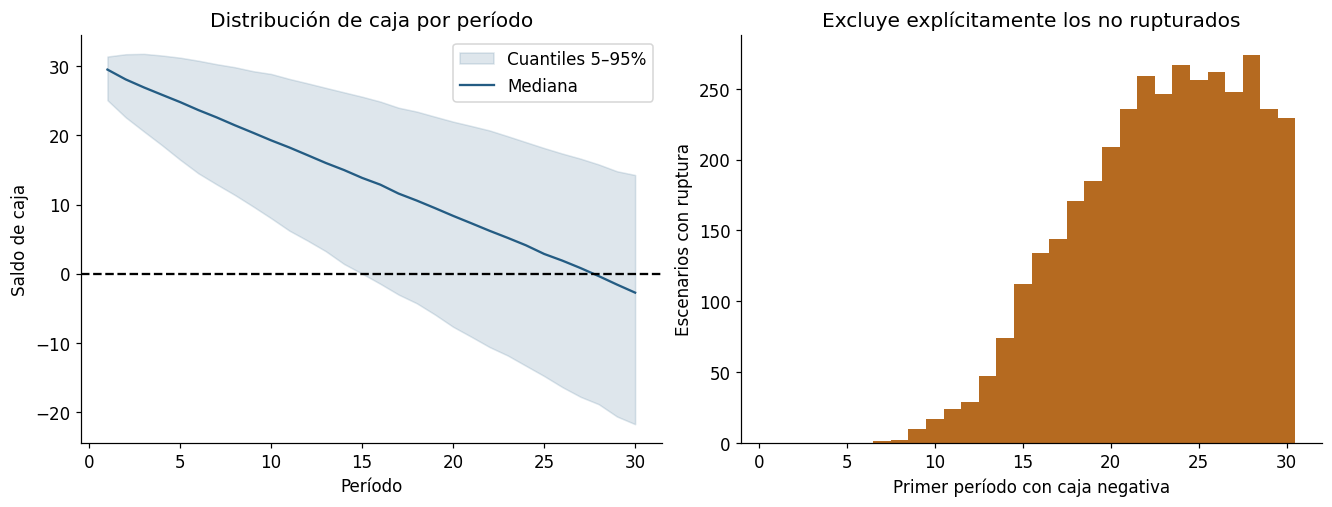

Sin ruptura hasta el final: 2328 de 6000


In [4]:
H=liquidity.paths.shape[1];breached=liquidity.first_breach<=H
print('Sin ruptura hasta el final:',int((~breached).sum()),'de',len(breached))
fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
q=np.quantile(liquidity.paths,[.05,.5,.95],axis=0);periods=np.arange(1,H+1)
axes[0].fill_between(periods,q[0],q[2],color='#245C83',alpha=.15,label='Cuantiles 5–95%')
axes[0].plot(periods,q[1],color='#245C83',label='Mediana');axes[0].axhline(0,color='black',linestyle='--')
axes[0].set(xlabel='Período',ylabel='Saldo de caja',title='Distribución de caja por período');axes[0].legend()
axes[1].hist(liquidity.first_breach[breached],bins=np.arange(.5,H+1.5),color='#B56A20')
axes[1].set(xlabel='Primer período con caja negativa',ylabel='Escenarios con ruptura',title='Excluye explícitamente los no rupturados')
plt.show()

## Dependencia frente a marginales
Se mantiene la distribución de pérdidas de mercado y del costo de financiación. Una permutación del costo rompe su acoplamiento de escenarios sin cambiar sus marginales empíricas. La diferencia de ES resulta de dependencia, no de un cambio de volatilidad marginal. Es una ablación, no un modelo alternativo calibrado.

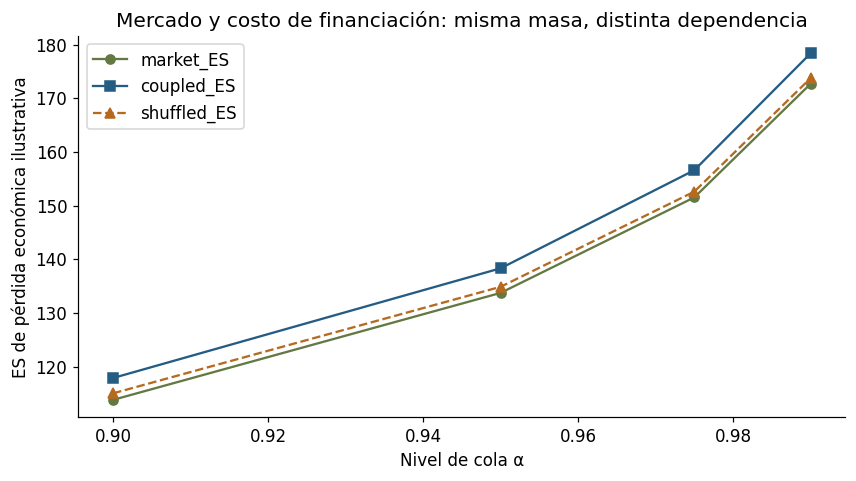

Correlación pérdida/costo acoplados: 0.7534875163348514
Correlación tras permutación: -0.022353980136203835


,alpha,market_ES,coupled_ES,shuffled_ES
0,0.900,113.79939,117.87177,115.01447
1,0.950,133.72731,138.30851,134.85951
2,0.975,151.51970,156.58542,152.59271
3,0.990,172.67052,178.35294,173.72215


In [5]:
funding_cost=.20*liquidity.max_shortfall
rng=np.random.default_rng(SEED);shuffled=funding_cost[rng.permutation(len(funding_cost))]
assert np.array_equal(np.sort(shuffled),np.sort(funding_cost))
joint=market+funding_cost;independent=market+shuffled
rows=[]
for alpha in [.90,.95,.975,.99]:
    rows.append(dict(alpha=alpha,market_ES=tail_risk(market,alpha).es,
        coupled_ES=tail_risk(joint,alpha).es,shuffled_ES=tail_risk(independent,alpha).es))
dependence_table=pd.DataFrame(rows);display(dependence_table.round(5))
print('Correlación pérdida/costo acoplados:',np.corrcoef(market,funding_cost)[0,1])
print('Correlación tras permutación:',np.corrcoef(market,shuffled)[0,1])
fig,ax=plt.subplots(figsize=(9,4.5))
for name,style,color in [('market_ES','o-','#637843'),('coupled_ES','s-','#245C83'),('shuffled_ES','^--','#B56A20')]:
    ax.plot(dependence_table.alpha,dependence_table[name],style,color=color,label=name)
ax.set(xlabel='Nivel de cola α',ylabel='ES de pérdida económica ilustrativa',title='Mercado y costo de financiación: misma masa, distinta dependencia')
ax.legend();plt.show()

## Contrato de cola y controles
VaR usa inversa generalizada empírica y ES integra exactamente 1−α. La convención anterior de VaR interpolado cambia en muestras discretas. La referencia de tres átomos permite verificar un resultado sin depender de simulación.

In [6]:
test=tail_risk([0,0,10,20],.625)
assert test.var==10. and np.isclose(test.es,(20+.5*10)/1.5)
for alpha in [.9,.95,.975,.99]:
    original=tail_risk(joint,alpha).es
    shifted=tail_risk(joint+7,alpha).es
    assert abs(shifted-original-7)<1e-9
assert np.all((liquidity.first_breach>=1)&(liquidity.first_breach<=H+1))
print('Masa de cola, traslación y marcador de censura: correctos.')

Masa de cola, traslación y marcador de censura: correctos.


## Límites y siguiente contraste
Se conocen las probabilidades de escenarios por simulación; no se estiman. La penalidad del 20% no representa una curva de fondeo observada. Faltan exposición por moneda, calendario real de pagos, valor realizable de colateral, haircuts y respuesta de tesorería. La permutación no crea independencia poblacional: destruye acoplamiento empírico con una sola permutación registrada.